# Amortized methods in geostatistics

**Check list execution**
* file
* path
* batch_size
* n_epoch

In [1]:
import matplotlib
import matplotlib.pyplot as plt

import numpy as np

import random
from tqdm import tqdm
import time
import os
import torchmin

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool, GCNConv

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

/home/aloret/PycharmProjects/Neural_ST_inference/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

In [6]:
file = "data/data20000_smaller"
# file = "data/data1000_smaller"

os.makedirs(file, exist_ok=True)
os.makedirs(file+"/samples", exist_ok=True)
os.makedirs(file+"/graphs", exist_ok=True)
os.makedirs(file+"/grids", exist_ok=True)

## Simulation

### Sampling

In [45]:
def sampling_matern(lambdaParent,lambdaDaughter,radiusCluster):

    xMin = 0
    xMax = 1
    yMin = 0
    yMax = 1

    rExt = radiusCluster  
    xMinExt = xMin - rExt
    xMaxExt = xMax + rExt
    yMinExt = yMin - rExt
    yMaxExt = yMax + rExt

    xDeltaExt = xMaxExt - xMinExt
    yDeltaExt = yMaxExt - yMinExt
    areaTotalExt = xDeltaExt * yDeltaExt  

    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent)  
    
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent)
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent)

    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent) 
    numbPoints = sum(numbPointsDaughter)

    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints) 
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints)) 
    xx0 = rho * np.cos(theta)
    yy0 = rho * np.sin(theta)

    xx = np.repeat(xxParent, numbPointsDaughter)
    yy = np.repeat(yyParent, numbPointsDaughter)

    xx = xx + xx0
    yy = yy + yy0

    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax))
    xx = xx[booleInside]
    yy = yy[booleInside]

    # data = {'x1': xx, 'x2': yy}
    # sample = pd.DataFrame(data)

    sample = gl.Db()
    sample.addColumns(xx,"x1")
    sample.addColumns(yy,"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample


def grid():

    sample = gl.Db()
    sample.addColumns(np.repeat(np.linspace(0,1,100),100),"x1")
    sample.addColumns(np.tile(np.linspace(0,1,100),100),"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample 

theta_size = 2

In [46]:
def simulation_matern(sample, theta_range, theta_std, plot=False):

    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range, param = 1, sill = theta_std**2, flagRange=False)  
    # model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range*np.sqrt(8), param = 1, sill = theta_std**2)
    err = gl.simtub(None, sample, model, None, nbsimu=1, seed=0, nbtuba = 1000)

    if plot:
            fig, axs = plt.subplots(1, 1, figsize=(7, 7), constrained_layout=True)

            axs.scatter(sample['x1'], sample['x2'], c=sample['Simu'], s=8) 
        
            axs.set_xlabel('x1')
            axs.set_ylabel('x2')
            axs.set_title('Simu Values with Selected Points')

            axs.set_xlim([0, 1])
            axs.set_ylim([0, 1])
            axs.axis('equal')

            plt.show()

    return sample

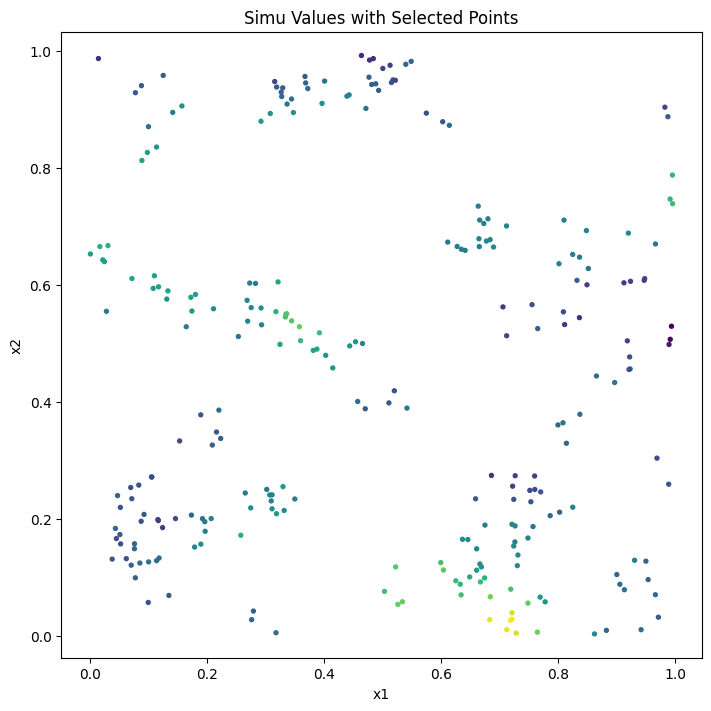


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 267

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = Simu - Locator = z1

In [134]:
sample = sampling_matern(50,250//50,.05)
theta_range, theta_std = .1, 1.
simulation_matern(sample, theta_range, theta_std, plot=True)

In [135]:
def datamaker(constant_product, n, m, as_grid=False, range_min=.05, range_max=.25,std_min=.1, std_max=1.,lambdaParent_min=10,lambdaParent_max=60,radiusCluster = 0.15,log=False):

    datalist=[]

    range_list = np.random.uniform(range_min,range_max,m)
    std_list = np.random.uniform(std_min, std_max,m)
    lambdaParent = np.random.uniform(lambdaParent_min, lambdaParent_max,(n,m))
    lambdaDaughter = constant_product / lambdaParent

    print("i : ", end='')

    for i in range(n):

        print(i, end='|')

        # pi = torch.randperm(m)

        for j in range(m):

            if as_grid :
                sample = grid() 
            else :
                sample = sampling_matern(lambdaParent[i,j],lambdaDaughter[i,j],radiusCluster)
            simu = simulation_matern(sample, range_list[j], std_list[j])
    
            theta = (range_list[j], std_list[j])
    
            datalist.append((simu,theta,j))

    return datalist

In [136]:
n_points = 250

n_train = 15
m_train = 2000

n_test = 10
m_test = 500

In [139]:
batch_size = 10
n_epochs = 30
n_epochs_test = 10

In [140]:
sampling_train = datamaker(n_points,
                           n_train,
                           m_train,
                           as_grid=False,
                           radiusCluster = 0.05)

i : 0|1|2|3|4|5|6|7|8|9|10|11|12|13|14|

In [141]:
sampling_test = datamaker(n_points, 
                          n_test, 
                          m_test, 
                          as_grid=False,
                          radiusCluster = 0.05)

i : 0|1|2|3|4|5|6|7|8|9|

### Graphs

In [142]:
def create_edge_graph(sample, threshold=.4, max_neighbors=10):
    coords = sample[['x1', 'x2']]
    node_features = torch.tensor(sample[['Simu']], dtype=torch.float)

    nearest_neighbors = cKDTree(coords) 

    edge_sources = []
    edge_destinations = []
    edge_features = []

    for i, coord in enumerate(coords):
        neighbors = nearest_neighbors.query_ball_point(coord, r=threshold)
        neighbors = [j for j in neighbors if j != i]

        if len(neighbors) > max_neighbors:
            neighbors = np.random.choice(neighbors, max_neighbors, replace=False)

        dists = np.linalg.norm(coords[neighbors] - coord, axis=1)
            
        edge_sources.extend(np.repeat(i,len(neighbors))) # [i] * len(neighbors)
        edge_destinations.extend(neighbors) # neighbors.tolist()

        edge_sources.extend(neighbors)
        edge_destinations.extend(np.repeat(i,len(neighbors)))
        
        edge_features.extend(np.concatenate([dists, dists]))

    edge_index = torch.tensor([edge_sources, edge_destinations], dtype=torch.long)
    edge_attr = torch.tensor(edge_features, dtype=torch.float).unsqueeze(1) # .view(-1, 1)

    return Data(x=node_features.unsqueeze(-1), edge_index=edge_index, edge_attr=edge_attr)# sizes=len(node_features))


In [143]:
def datamaker_graph(simu, threshold = 0.4,max_neighbors = 10):

    n = len(simu)
    datalist = []

    t = tqdm(range(0, n),total=n)

    for i in t:
        
        data = create_edge_graph(simu[i][0], threshold, max_neighbors)
        theta = torch.tensor(simu[i][1])
        deepset = torch.tensor(simu[i][2])

        datalist.append((data, theta, deepset))

    return datalist

In [231]:
dataset_graph = datamaker_graph(sampling_train)
loader_graph = DataLoader(dataset_graph, batch_size, shuffle=True)

dataset_graph_test = datamaker_graph(sampling_test)
loader_graph_test = DataLoader(dataset_graph_test, len(sampling_test), shuffle=False)

dataset_graph[2]

  2%|███▏                                                                                                                                                                              | 538/30000 [00:07<07:16, 67.52it/s]


KeyboardInterrupt: 

### Grid

In [145]:
def points_to_grid(sample, nb_bins=100):
    
    bin_size = 1.0 / nb_bins

    x1 = torch.tensor(sample['x1'], dtype=torch.float32)
    x2 = torch.tensor(sample['x2'], dtype=torch.float32)
    values = torch.tensor(sample['Simu'], dtype=torch.float32)
    
    ix = torch.clamp((x1 / bin_size).long(), max=nb_bins - 1)
    iy = torch.clamp((x2 / bin_size).long(), max=nb_bins - 1)

    flat_idx = ix * nb_bins + iy
    
    # value_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
    # count_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
        
    # value_flat.index_add_(0, flat_idx, values)
    # count_flat.index_add_(0, flat_idx, torch.ones_like(values))

    # mean_grid = torch.empty_like(value_flat)
    # mean_grid[:] = float('nan')
    # mask = count_flat > 0
    # mean_grid[mask] = value_flat[mask] / count_flat[mask]

    # return mean_grid.view(nb_bins, nb_bins)

    value_flat = torch.full((nb_bins * nb_bins,), float('nan'))

    unique_idx = flat_idx.unique()
    for idx in unique_idx:
        indices_in_cell = torch.where(flat_idx == idx)[0]
        chosen = indices_in_cell[torch.randint(0, len(indices_in_cell), (1,))]
        value_flat[idx] = values[chosen]

    return value_flat.view(nb_bins, nb_bins)

In [146]:
def datamaker_grid(simu,bins = 100):

    n = len(simu)
    datalist = []
    
    t = tqdm(range(0, n),total=n)
    
    for i in t:

        data = points_to_grid(simu[i][0], bins)
        mask = (~torch.isnan(data)).float()
        data = torch.nan_to_num(data, nan=0.)
        data = torch.stack([data, mask], dim=0) 

        
        theta = torch.tensor(simu[i][1])
        deepset = torch.tensor(simu[i][2])
        
        datalist.append((data, theta, deepset))               
    
    return datalist

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:15<00:00, 314.02it/s]


tensor([0.1674, 0.4717], dtype=torch.float64) tensor(7)


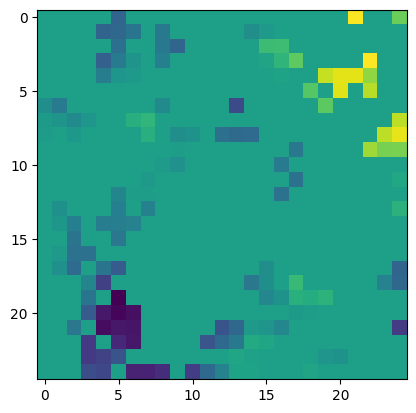

In [147]:
dataset_grid = datamaker_grid(sampling_train,bins = 25)
loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)

dataset_grid_test = datamaker_grid(sampling_test,bins = 25)
loader_grid_test = DataLoader(dataset_grid_test, len(sampling_test), shuffle=False)

plt.imshow(dataset_grid[7][0][0])
print(dataset_grid[7][1], dataset_grid[7][2])

## Save and Load

### Save

### Load

In [7]:
batch_size = 100
n_epochs = 150
n_epochs_test = 10

In [8]:
class GraphDataset(Dataset):
    def __init__(self, theta, deepset, name="train"):
        self.theta = theta
        self.deepset = deepset
        self.name = name

    def __len__(self):
        return len(self.theta)

    def __getitem__(self, idx):
        data = torch.load(file+"/graphs/"+self.name+"_graph"+str(idx)+".pt", weights_only=False)
        return (data, self.theta[idx], self.deepset[idx])

class GridDataset(Dataset):
    def __init__(self, theta, deepset, name="train"):
        self.theta = theta
        self.deepset = deepset
        self.name = name

    def __len__(self):
        return len(self.theta)

    def __getitem__(self, idx):
        data = torch.load(file+"/grids/"+self.name+"_grid"+str(idx)+".pt")
        return (data, self.theta[idx], self.deepset[idx])        

In [9]:
train_theta = torch.load(file+"/train_theta.pt")
train_deepset = torch.load(file+"/train_deepset.pt")

nm_train = len(train_theta)
m_train = len(train_deepset.unique())
n_train = nm_train // m_train

test_theta = torch.load(file+"/test_theta.pt")
test_deepset = torch.load(file+"/test_deepset.pt")

nm_test = len(test_theta)
m_test = len(test_deepset.unique())
n_test = nm_test // m_test

In [10]:
dataset_graph = GraphDataset(train_theta, train_deepset)
dataset_graph_test = GraphDataset(test_theta, test_deepset, "test")

dataset_grid = GridDataset(train_theta, train_deepset)
dataset_grid_test = GridDataset(test_theta, test_deepset, "test")


loader_graph = DataLoader(dataset_graph, batch_size, shuffle=True)
loader_graph_test = DataLoader(dataset_graph_test, nm_test, shuffle=False)

loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)
loader_grid_test = DataLoader(dataset_grid_test, nm_test, shuffle=False)

sampling_test = [(gl.Db.createFromNF(file+"/samples/test_sample"+str(i)), test_theta[i], test_deepset[i]) for i in range(nm_test)]

In [11]:
dataset_graph[2]

(Data(x=[253, 1], edge_index=[2, 5060], edge_attr=[5060, 1]),
 tensor([0.0699, 0.7942], dtype=torch.float64),
 tensor(2))

tensor([0.1674, 0.4717], dtype=torch.float64) tensor(7)


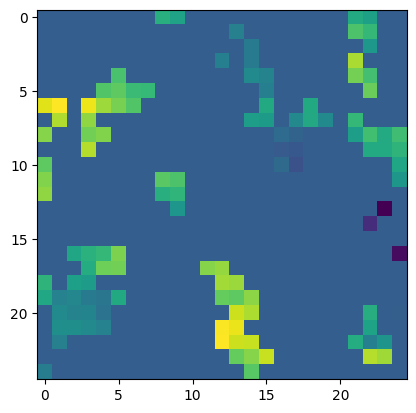

In [12]:
plt.imshow(dataset_grid[9][0][0])
print(dataset_grid[7][1], dataset_grid[7][2])

In [13]:
print(sampling_test[1][0])


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 276

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = Simu - Locator = z1



In [14]:
print(len(dataset_graph))

30000


## Utils

In [15]:
def unique_preserve_order(x):
    seen = []
    out = []
    for v in x.tolist():
        if v not in seen:
            seen.append(v)
            out.append(v)
    return torch.tensor(out, device=x.device)


def map_deepset(deepset, theta):
    unique_ds = unique_preserve_order(deepset)

    deepset_mapped = torch.tensor(
        [unique_ds.tolist().index(int(ds)) for ds in deepset],
        device=device
    )

    theta = torch.stack([theta[deepset == v][0] for v in unique_ds])

    return deepset_mapped, theta

In [16]:
def baseline_mae(dataset):
    all_thetas = torch.stack([data[1] for data in dataset])
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

theta_size = 2

In [17]:
id_path = "gobal_smaller"
path = f"results/{id_path}-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest" # -{n_points}npoints"

os.makedirs(path, exist_ok=True)
os.makedirs(path+"/loss_evolution", exist_ok=True)
os.makedirs(path+"/conclusion_graphs", exist_ok=True)
os.makedirs(path+"/models", exist_ok=True)
os.makedirs(path+"/bonus", exist_ok=True)

## GNN

In [24]:
class GNN_network(nn.Module):
    def __init__(self, in_channels=1, hidden=32, out_dim=2, nls=False):
        super().__init__()

        self.nls = nls

        self.conv1 = GCNConv(in_channels, hidden)
        self.conv2 = GCNConv(hidden, hidden) 

        self.dense = nn.Sequential(
            nn.Linear(hidden+2*nls, 32),
            nn.ReLU(),
            nn.Linear(32, out_dim)  
        )

        # self.head1 = nn.Linear(32, 1)

        # self.head2 = nn.Sequential(
        #     nn.Dropout(0.2),
        #     nn.Linear(32, 1)
        # )

    def forward(self, data, deepset=None, theta=None):
        
        x = F.relu(self.conv1(data.x, data.edge_index , edge_weight=data.edge_attr))
        x = F.relu(self.conv2(x, data.edge_index , edge_weight=data.edge_attr))

        x = global_mean_pool(x, data.batch)     # [batch_size, hidden_dim]

        if not self.nls :
            x = global_mean_pool(x, deepset)   # [nb_deepset, hidden_dim]
        else :
            x = torch.cat((x, theta.float()),dim=1)

        out = self.dense(x)
        # out = torch.cat([self.head1(out), self.head2(out)], dim=1)
        return out 


In [25]:
def train_gnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = []

    for i, (batched_data, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device), theta.to(device), deepset.to(device)

        deepset_mapped, theta = map_deepset(deepset, theta)

        output = model(batched_data, deepset_mapped)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss.append(torch.abs(output - theta))

    return torch.cat(sum_loss,dim=0)



In [26]:
model_graph = GNN_network(in_channels=1)

optimizer_graph = torch.optim.Adam(model_graph.parameters(), lr=1e-4)

In [27]:
all_loss_train_graph = [] # torch.zeros((n_epochs, n_train,theta_size))
all_loss_test_graph = [] # torch.zeros((n_epochs//n_epochs_test, n_test,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_graph = time.time()

for epoch in t:
    
    loss = train_gnn(
        model_graph,
        optimizer_graph,
        loader_graph,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_graph.append(loss.detach().numpy())

    # test
    if (epoch+1)%n_epochs_test == 0 :
        time_test_graph = time.time()
        for data_test, theta_test, deepset_test in loader_graph_test : 
            # deepset_mapped_test, theta_test = map_deepset(deepset_test, theta_test)
            # output = model_graph(data_test,deepset_mapped_test)
            output = model_graph(data_test,torch.arange(len(theta_test)))
            l = torch.abs(output - theta_test)
        time_test_graph = time.time() - time_test_graph
        time_train_graph -= time_test_graph
        all_loss_test_graph.append(l.detach().numpy())
        theta_final_graph = output.detach().numpy()

time_train_graph = time.time() - time_train_graph

print(f"Time to train : {time_train_graph:.2f}s")

# all_loss_train_graph = torch.stack(all_loss_train_graph).detach().numpy()
# all_loss_test_graph = torch.stack(all_loss_test_graph).detach().numpy()
print("Train loss :", np.mean(all_loss_train_graph[-1],axis=0), "±", np.std(all_loss_train_graph[-1],axis=0))
print("Test loss :", np.mean(all_loss_test_graph[-1],axis=0), "±", np.std(all_loss_test_graph[-1],axis=0))

Epoch 150/150: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [2:04:54<00:00, 49.96s/it, loss=tensor([0.0448, 0.0906], dtype=torch.float64, grad_fn=<MeanBackward1>)]

Time to train : 7682.12s
Train loss : [0.04479447 0.09062597] ± [0.0291155  0.07824237]
Test loss : [0.0447153  0.09083881] ± [0.0292025  0.07945658]


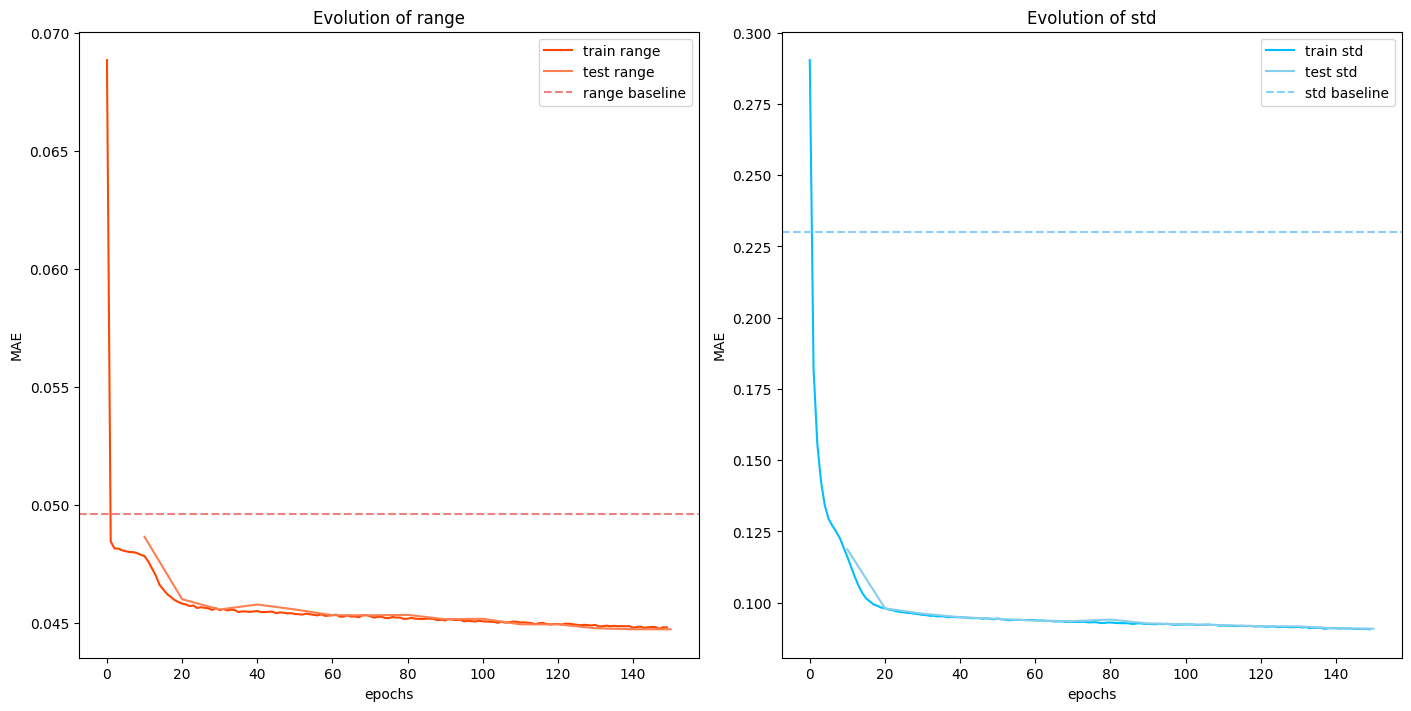

In [28]:
fig_gnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot([l.mean(axis=0)[0] for l in all_loss_train_graph], 'orangered', label='train range')
ax[1].plot([l.mean(axis=0)[1] for l in all_loss_train_graph], 'deepskyblue',label='train std')
ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[0] for l in all_loss_test_graph], 'coral', label='test range')
ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[1] for l in all_loss_test_graph], 'skyblue',label='test std')

based, _ = baseline_mae(dataset_graph)
ax[0].axhline(based[0],color='lightcoral', ls='--', label='range baseline')
plt.axhline(based[1],color='lightskyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

In [29]:
# fig_gnn.savefig(path+"/loss_evolution"+"/gnn.pdf", format="pdf", bbox_inches="tight")
fig_gnn.savefig(path+"/loss_evolution"+"/gnn_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_graph.state_dict(), path+"/models"+"/gnn_simple_model.pth")

### Quantiles

### Bootstrap

## CNN

In [18]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2, nls=False):
        super().__init__()

        self.nls = nls
        
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 10, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 5, padding=1),
            nn.ReLU(),
        )
        
        self.pool = nn.AdaptiveAvgPool2d(1) 
        
        self.dense = nn.Sequential(
            nn.Linear(hidden+2*nls, 32),
            nn.ReLU(),
            nn.Linear(32, out_dim)  
        )

    def forward(self, x, deepset=None, theta=None):
        h = self.conv(x)
        h = self.pool(h).view(h.shape[0], -1)

        if not self.nls :
            h = global_mean_pool(h, deepset)   # [nb_deepset, hidden_dim]
        else :
            h = torch.cat((h, theta.float()),dim=1)
        
        out = self.dense(h)
        return out

class CNN_network_nodense(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(16)
        self.conv_out = nn.Sequential(
            nn.Conv2d(hidden, hidden//2, 4, padding=0,stride=4),
            nn.ReLU(),
            nn.Dropout2d(p=0.05),
            nn.Conv2d(hidden//2, 2, 4, padding=0,stride=4)
        )

    def forward(self, x, deepset):
        
        h = self.conv(x)
        
        h = self.pool(h)

        h_shape = torch.tensor(h.shape)
            
        h = global_mean_pool(h.reshape((h_shape[0], -1)), deepset)   # [nb_deepset, hidden_dim]

        h = h.view(h.size(0), h_shape[1], h_shape[2], h_shape[3])
        out = self.conv_out(h)
        out = out.view(h.shape[0], -1)
        
        return out

In [19]:
def train_cnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = []

    for i, (batched_data, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device), theta.to(device), deepset.to(device)

        deepset_mapped, theta = map_deepset(deepset, theta)
        
        output = model(batched_data, deepset_mapped)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss.append(torch.abs(output - theta))

    return torch.cat(sum_loss,dim=0)


In [20]:
model_grid = CNN_network(in_channels=2).to(device)

optimizer_grid = torch.optim.Adam(model_grid.parameters(), lr=1e-4)

In [21]:
all_loss_train_grid = [] # torch.zeros((n_epochs, n_train,theta_size))
all_loss_test_grid = [] # torch.zeros((n_epochs//n_epochs_test, n_test,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_grid = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid,
        optimizer_grid,
        loader_grid,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_grid.append(loss.detach().numpy())

    # test
    if (epoch+1)%n_epochs_test == 0 :
        time_test_grid = time.time()
        for data_test, theta_test, deepset_test in loader_grid_test : 
            # deepset_mapped_test, theta_test = map_deepset(deepset_test, theta_test)
            # output = model_grid(data_test,deepset_mapped_test)
            output = model_grid(data_test,torch.arange(len(theta_test)))
            l = torch.abs(output - theta_test)
        time_test_grid = time.time() - time_test_grid
        time_train_grid -= time_test_grid
        all_loss_test_grid.append(l.detach().numpy())
        theta_final_grid = output.detach().numpy()

time_train_grid = time.time() - time_train_grid

print(f"Time to train : {time_train_grid:.2f}s")

print("Train loss :", np.mean(all_loss_train_grid[-1],axis=0), "±", np.std(all_loss_train_grid[-1],axis=0))
print("Test loss :", np.mean(all_loss_test_grid[-1],axis=0), "±", np.std(all_loss_test_grid[-1],axis=0))

Epoch 150/150: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [29:24<00:00, 11.76s/it, loss=tensor([0.0305, 0.0680], dtype=torch.float64, grad_fn=<MeanBackward1>)]

Time to train : 1784.34s
Train loss : [0.03050508 0.06802083] ± [0.02387537 0.06272791]
Test loss : [0.03165804 0.0719992 ] ± [0.0244698  0.06369933]


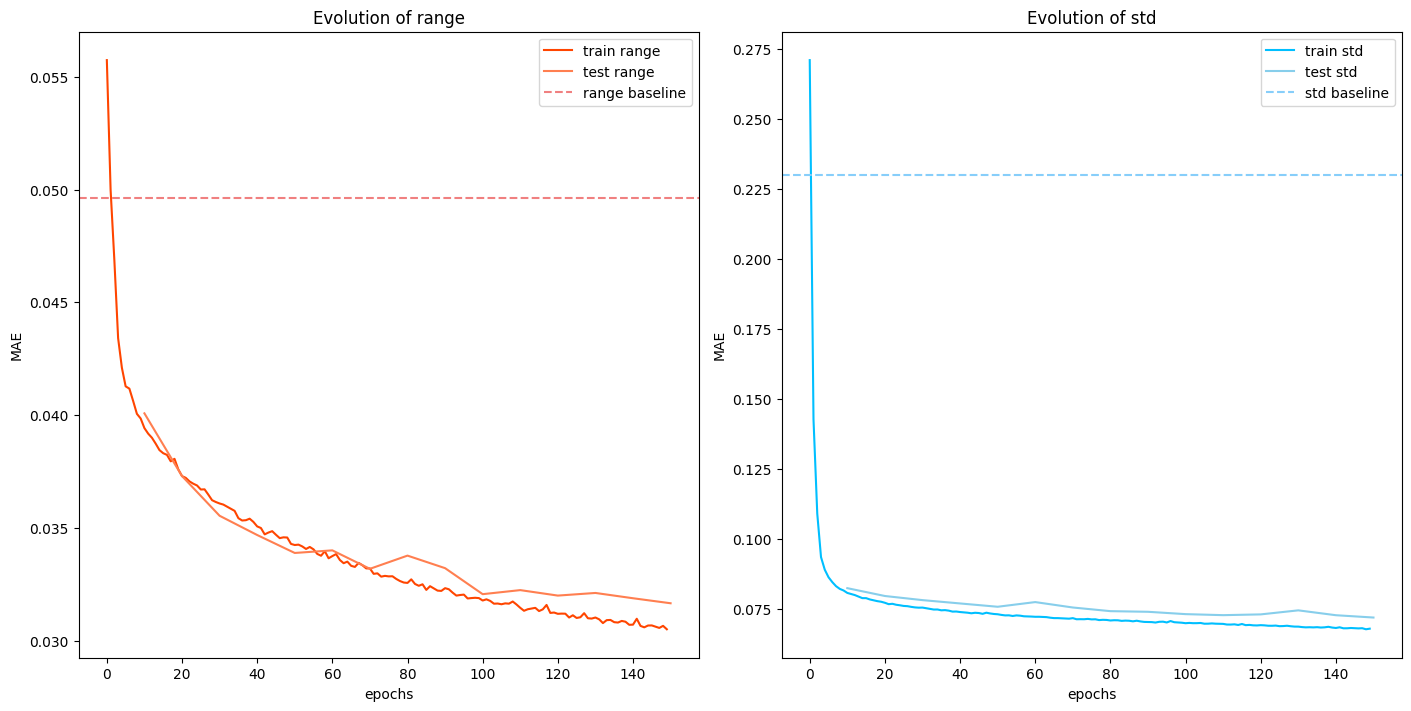

In [22]:
fig_cnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot([l.mean(axis=0)[0] for l in all_loss_train_grid], 'orangered', label='train range')
ax[1].plot([l.mean(axis=0)[1] for l in all_loss_train_grid], 'deepskyblue',label='train std')
ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[0] for l in all_loss_test_grid], 'coral', label='test range')
ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[1] for l in all_loss_test_grid], 'skyblue',label='test std')

based, _ = baseline_mae(dataset_grid)
ax[0].axhline(based[0],color='lightcoral', ls='--', label='range baseline')
plt.axhline(based[1],color='lightskyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

In [23]:
# fig_cnn.savefig(path+"/loss_evolution"+"/cnn.pdf", format="pdf", bbox_inches="tight")
fig_cnn.savefig(path+"/loss_evolution"+"/cnn_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_grid.state_dict(), path+"/models"+"/cnn_model.pth")

## Maximum likelihood

In [39]:
def mle_gstlearn(db):
    
    modelnew = gl.Model.createFromParam(gl.ECov.MATERN,param = 1)
    mop = gl.ModelOptimParam.create(False) 
    modelnew.fitNew(db=db,verbose = False, mop = mop, nb_neighVecchia=20)

    # print(modelnew.getCovAniso(0).getSill(0,0) / modelnew.getCovAniso(0).getScale(0)**2)
   
    return modelnew.getCovAniso(0).getScale(0), np.sqrt(modelnew.getCovAniso(0).getSill(0,0))

In [40]:
all_loss_test_ML = np.zeros((len(sampling_test),theta_size))
theta_final_ML = np.zeros((len(sampling_test),theta_size))

time_test_ML = time.time()

for i, (data_test, theta_test, _) in enumerate(sampling_test) : 

    # output, _ = mle_matern(data_test[["x1","x2"]],data_test["Simu"])
    output = mle_gstlearn(data_test)

    all_loss_test_ML[i] = np.abs(output - np.array(theta_test))
    theta_final_ML[i] = output

    print(i, end='|')

    # print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML

print(f"\n\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

/tmp/ipykernel_7704/4016525869.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  all_loss_test_ML[i] = np.abs(output - np.array(theta_test))


0|1|2|3|4|5|6|7|8|9|10|11|12|13|14|15|16|17|18|19|20|21|22|23|24|25|26|27|28|29|30|31|32|33|34|35|36|37|38|39|40|41|42|43|44|45|46|47|48|49|50|51|52|53|54|55|56|57|58|59|60|61|62|63|64|65|66|67|68|69|70|71|72|73|74|75|76|77|78|79|80|81|82|83|84|85|86|87|88|89|90|91|92|93|94|95|96|97|98|99|100|101|102|103|104|105|106|107|108|109|110|111|Warning, optimization return code is -1
112|113|114|115|116|117|118|119|120|121|122|123|124|125|126|Warning, optimization return code is -1
127|128|129|130|131|132|133|134|135|136|137|138|139|140|141|142|143|144|145|146|147|148|149|150|151|152|153|154|155|156|157|158|159|160|161|162|163|164|165|166|167|168|169|170|171|172|173|174|175|176|177|178|179|180|181|182|183|184|185|186|187|188|189|190|191|192|193|194|195|196|197|198|199|200|201|202|203|204|205|206|207|208|209|210|211|212|213|214|215|216|217|218|219|220|221|222|223|224|225|226|227|228|229|230|231|232|233|234|235|236|237|238|239|240|241|242|243|244|245|246|247|248|249|250|251|252|253|254|255|256|25

## NLS

### Classifier

In [30]:
class GridNLSDataset(Dataset):
    def __init__(self, theta, deepset):
        self.theta = theta
        self.deepset = deepset

        self.theta_perm = theta.clone()
        for i in range(n_train):
            pi = torch.randperm(m_train)
            self.theta_perm[i*m_train+torch.arange(m_train)] = theta[i*m_train+pi[torch.arange(m_train)]]
            
    def __len__(self):
        return len(self.theta)*2

    def __getitem__(self, idx):

        nm = len(self.theta)

        if idx < nm :
            data = torch.load(file+"/grids/train_grid"+str(idx)+".pt", weights_only=False)
            return (data, self.theta[idx], torch.tensor(1))
        else :
            data = torch.load(file+"/grids/train_grid"+str(idx - nm)+".pt", weights_only=False)
            return (data, self.theta_perm[idx - nm], torch.tensor(0))

dataset_grid_nls = GridNLSDataset(train_theta, train_deepset)
loader_grid_nls = DataLoader(dataset_grid_nls, batch_size, shuffle=True)


# class GraphNLSDataset(Dataset):
#     def __init__(self, theta, deepset):
#         self.theta = theta
#         self.deepset = deepset

#         self.theta_perm = theta.clone()
#         for i in range(n_train):
#             pi = torch.randperm(m_train)
#             self.theta_perm[i*m_train+torch.arange(m_train)] = theta[i*m_train+pi[torch.arange(m_train)]]
            
#     def __len__(self):
#         return len(self.theta)*2

#     def __getitem__(self, idx):

#         nm = len(self.theta)

#         if idx < nm :
#             data = torch.load(file+"/graphs/train_graph"+str(idx)+".pt", weights_only=False)
#             return (data, self.theta[idx], torch.tensor(1))
#         else :
#             data = torch.load(file+"/graphs/train_graph"+str(idx - nm)+".pt", weights_only=False)
#             return (data, self.theta_perm[idx - nm], torch.tensor(0))

# dataset_graph_nls = GraphNLSDataset(train_theta, train_deepset)
# loader_graph_nls = DataLoader(dataset_graph_nls, batch_size, shuffle=True)

In [31]:
def train_nls(model, optimizer, loader):
    
    model.train()
    CE = nn.CrossEntropyLoss() # torch.nn.BCELoss(reduction="mean") 
    
    sum_loss = []

    for i, (x, theta, classi) in enumerate(loader):
        optimizer.zero_grad()

        x, theta, label = x.to(device), theta.to(device), classi.to(device).flatten()

        output = model(x, theta=theta)
        
        batch_loss = CE(output, label)
        
        batch_loss.backward()
        optimizer.step()
        
        sum_loss.append(batch_loss.item())

    return sum_loss

In [32]:
# model_nls = GNN_network(in_channels=1, nls=True).to(device)
model_nls = CNN_network(in_channels=2, nls=True).to(device)

optimizer_nls = torch.optim.Adam(model_nls.parameters(), lr=1e-3)

Epoch 150/150: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [1:01:09<00:00, 24.46s/it, loss=0.0956619191945841]

Time to train : 3669.22s


Text(0, 0.5, 'Cross Entropy')

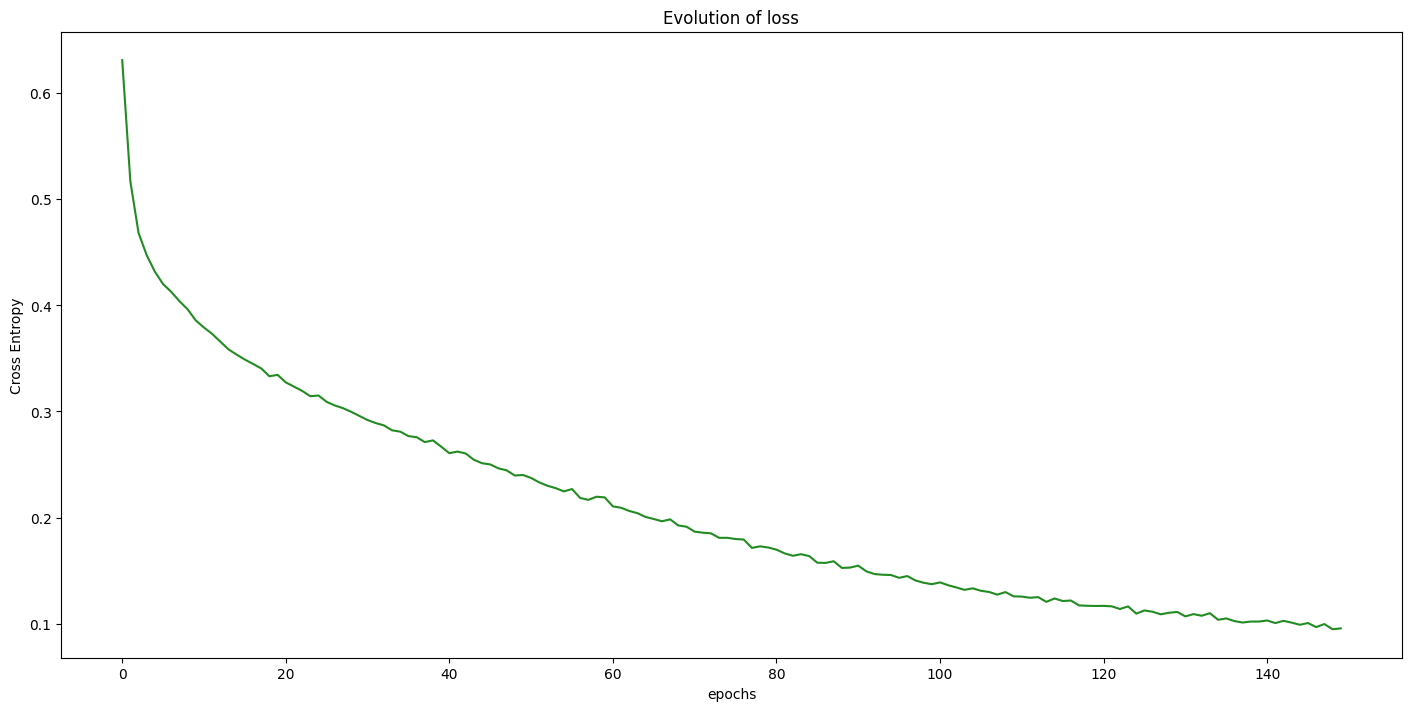

In [33]:
all_loss_train_nls=np.zeros((n_epochs,))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_nls = time.time()

for epoch in t:
    
    loss = train_nls(
        model_nls,
        optimizer_nls,
        loader_grid_nls,
        # loader_graph_nls,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{np.mean(loss)}")
    all_loss_train_nls[epoch] = np.mean(loss)

time_train_nls = time.time() - time_train_nls

print(f"Time to train : {time_train_nls:.2f}s")

fig_nls, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_nls, 'forestgreen')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

In [34]:
# fig_nls.savefig(path+"/loss_evolution"+"/gnn.pdf", format="pdf", bbox_inches="tight")
fig_nls.savefig(path+"/loss_evolution"+"/nls-classifier_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_nls.state_dict(), path+"/models"+"/nls-classifier_model.pth")

### Calibration

### Estimation

In [35]:
def estimate_likelihood_surface(model, simu, theta_grid):
    
    model.eval()
    
    L_values = []
    simu = simu.to(device)
    
    with torch.no_grad():
        t = tqdm(theta_grid)
        for theta in t:
            
            theta_t = theta.clone().unsqueeze(0).tile((m_test*n_test, 1)).to(device)
            
            h = model(simu, theta=theta_t)
            p = torch.softmax(h, dim=1)[:, 1] 
            
            L = p / (1 - p)

            # L = torch.log(L.unsqueeze(0)).detach().numpy()
            # L = torch.tensor(lg.predict_proba(L.T)[0, 1])

            L_values.append(L)
            
    return torch.stack(L_values)

In [36]:
range_min, range_max = 0.05, 0.25
std_min, std_max = 0.1, 1.0

bounds = [(range_min, range_max), (std_min, std_max)]

n_range = 20
n_std = 20

range_vals = torch.linspace(range_min, range_max, n_range)
std_vals = torch.linspace(std_min, std_max, n_std)

R, S = torch.meshgrid(range_vals, std_vals, indexing='ij')
theta_grid = torch.stack([R.flatten(), S.flatten()], dim=1)

In [38]:
time_test_nls = time.time()

with torch.no_grad():
    for data_test, theta_test, _ in loader_grid_test : 
        L_values = estimate_likelihood_surface(model_nls, data_test, theta_grid)
        output = theta_grid[torch.argmax(L_values,dim=0)]
        all_loss_test_nls = torch.abs(output - theta_test).detach().numpy()
        theta_final_nls = output.detach().numpy()
        
time_test_nls = time.time() - time_test_nls

print(f"\nTime to test : {time_test_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_nls,axis=0), "±", np.std(all_loss_test_nls,axis=0))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [03:12<00:00,  2.08it/s]


Time to test : 193.79s
Test loss : [0.04823189 0.11234067] ± [0.03774995 0.09952009]


## Conclusion

/tmp/ipykernel_7704/4121961618.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_7704/4121961618.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


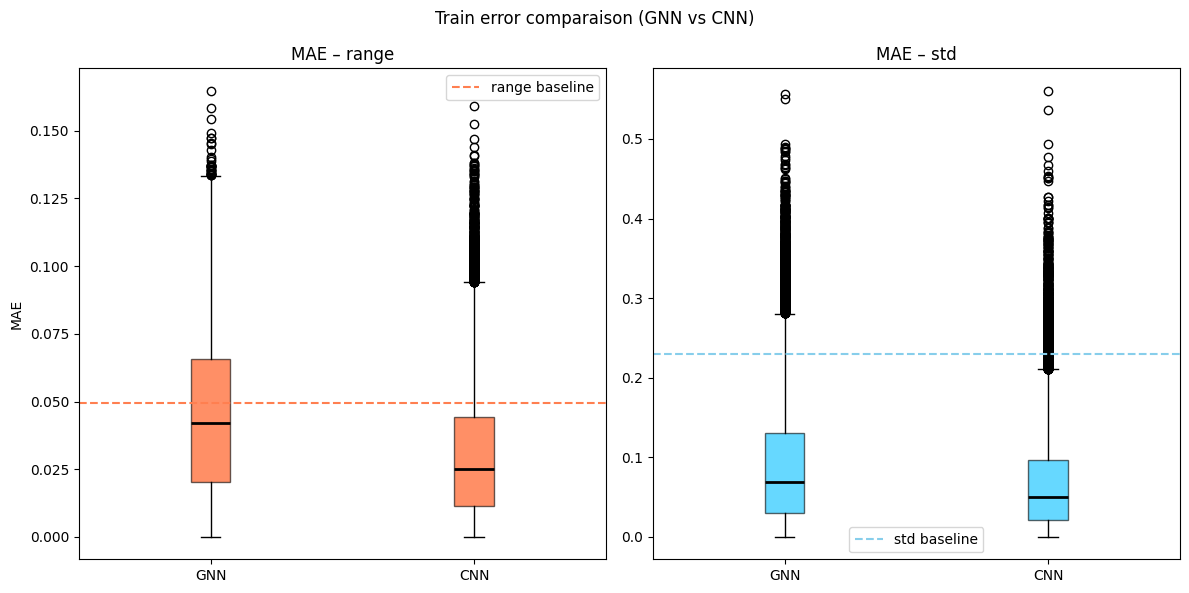

In [41]:
methods = ['GNN', 'CNN']

loss_range = [
    all_loss_train_graph[-1][:, 0],
    all_loss_train_grid[-1][:, 0],
]

loss_std = [
    all_loss_train_graph[-1][:, 1],
    all_loss_train_grid[-1][:, 1],
]

### Boxplot
fig_box_train, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='orangered', alpha=0.6), 
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='deepskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Train error comparaison (GNN vs CNN)")
plt.tight_layout()
plt.show()

# fig_box_train.savefig(path+"/conclusion_graphs"+"/score_train.pdf", format="pdf", bbox_inches="tight")
fig_box_train.savefig(path+"/conclusion_graphs"+"/score_train.png", format="png", bbox_inches="tight")

/tmp/ipykernel_7704/3290294810.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_7704/3290294810.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


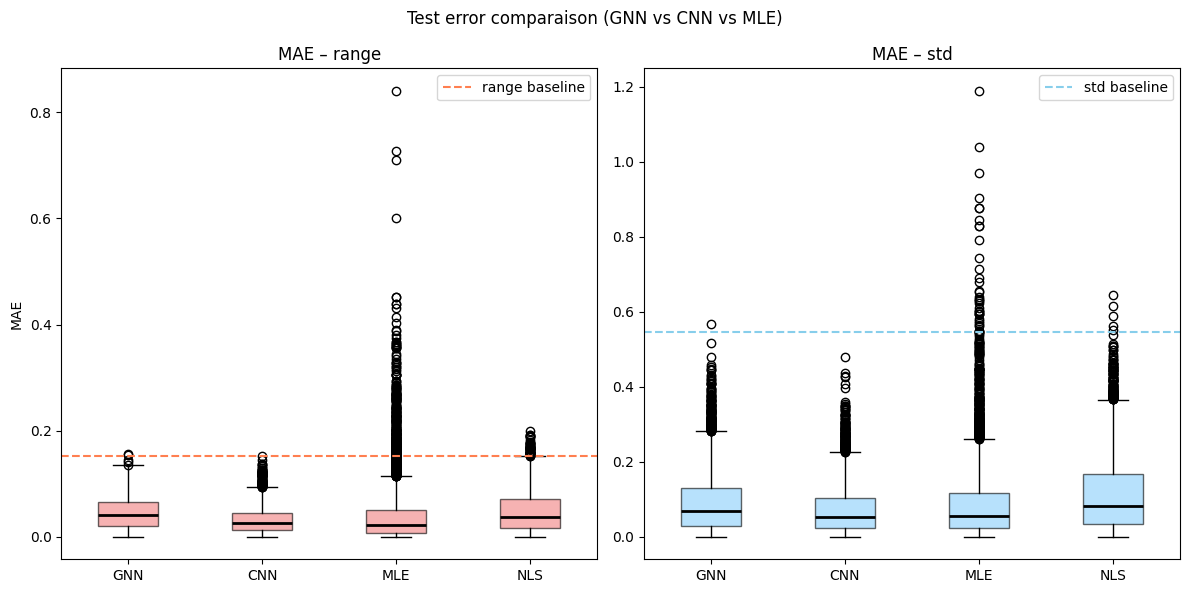

In [52]:
methods = ['GNN', 'CNN', 'MLE', 'NLS']

loss_range = [
    all_loss_test_graph[-1][:, 0],
    all_loss_test_grid[-1][:, 0],
    all_loss_test_ML[:, 0],
    all_loss_test_nls[:, 0]
]

loss_std = [
    all_loss_test_graph[-1][:, 1],
    all_loss_test_grid[-1][:, 1],
    all_loss_test_ML[:, 1],
    all_loss_test_nls[:, 1]
]

### Boxplot
fig_box_test, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Test error comparaison (GNN vs CNN vs MLE)")
plt.tight_layout()
plt.show()

# fig_box_test.savefig(path+"/conclusion_graphs"+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(path+"/conclusion_graphs"+"/score_test.png", format="png", bbox_inches="tight")

axs[0].set_ylim(top=based[0]+.05)
axs[1].set_ylim(top=based[1]+.05)

fig_box_test.savefig(path+"/conclusion_graphs"+"/score_test_cropped.png", format="png", bbox_inches="tight")

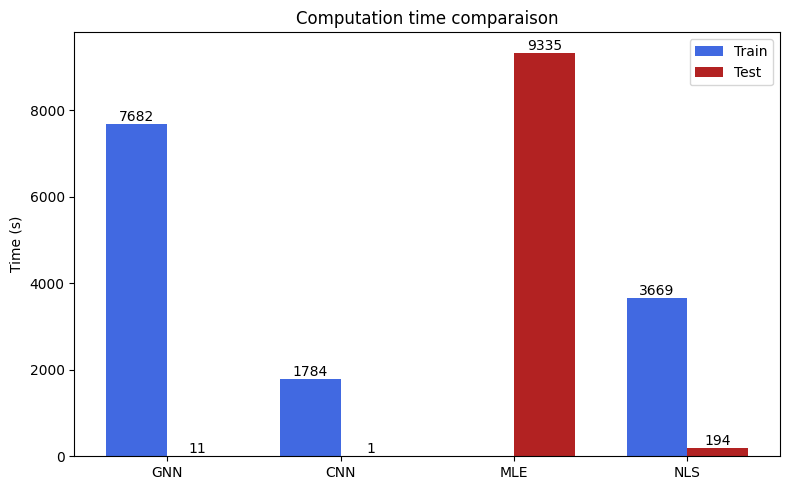

In [43]:
### Time
train_times = [time_train_graph, time_train_grid, np.nan, time_train_nls]  
test_times = [time_test_graph, time_test_grid, time_test_ML, time_test_nls]

x = np.arange(len(methods))
width = 0.35

fig_time, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

# fig_time.savefig(path+"/conclusion_graphs"+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(path+"/conclusion_graphs"+"/time.png", format="png", bbox_inches="tight")

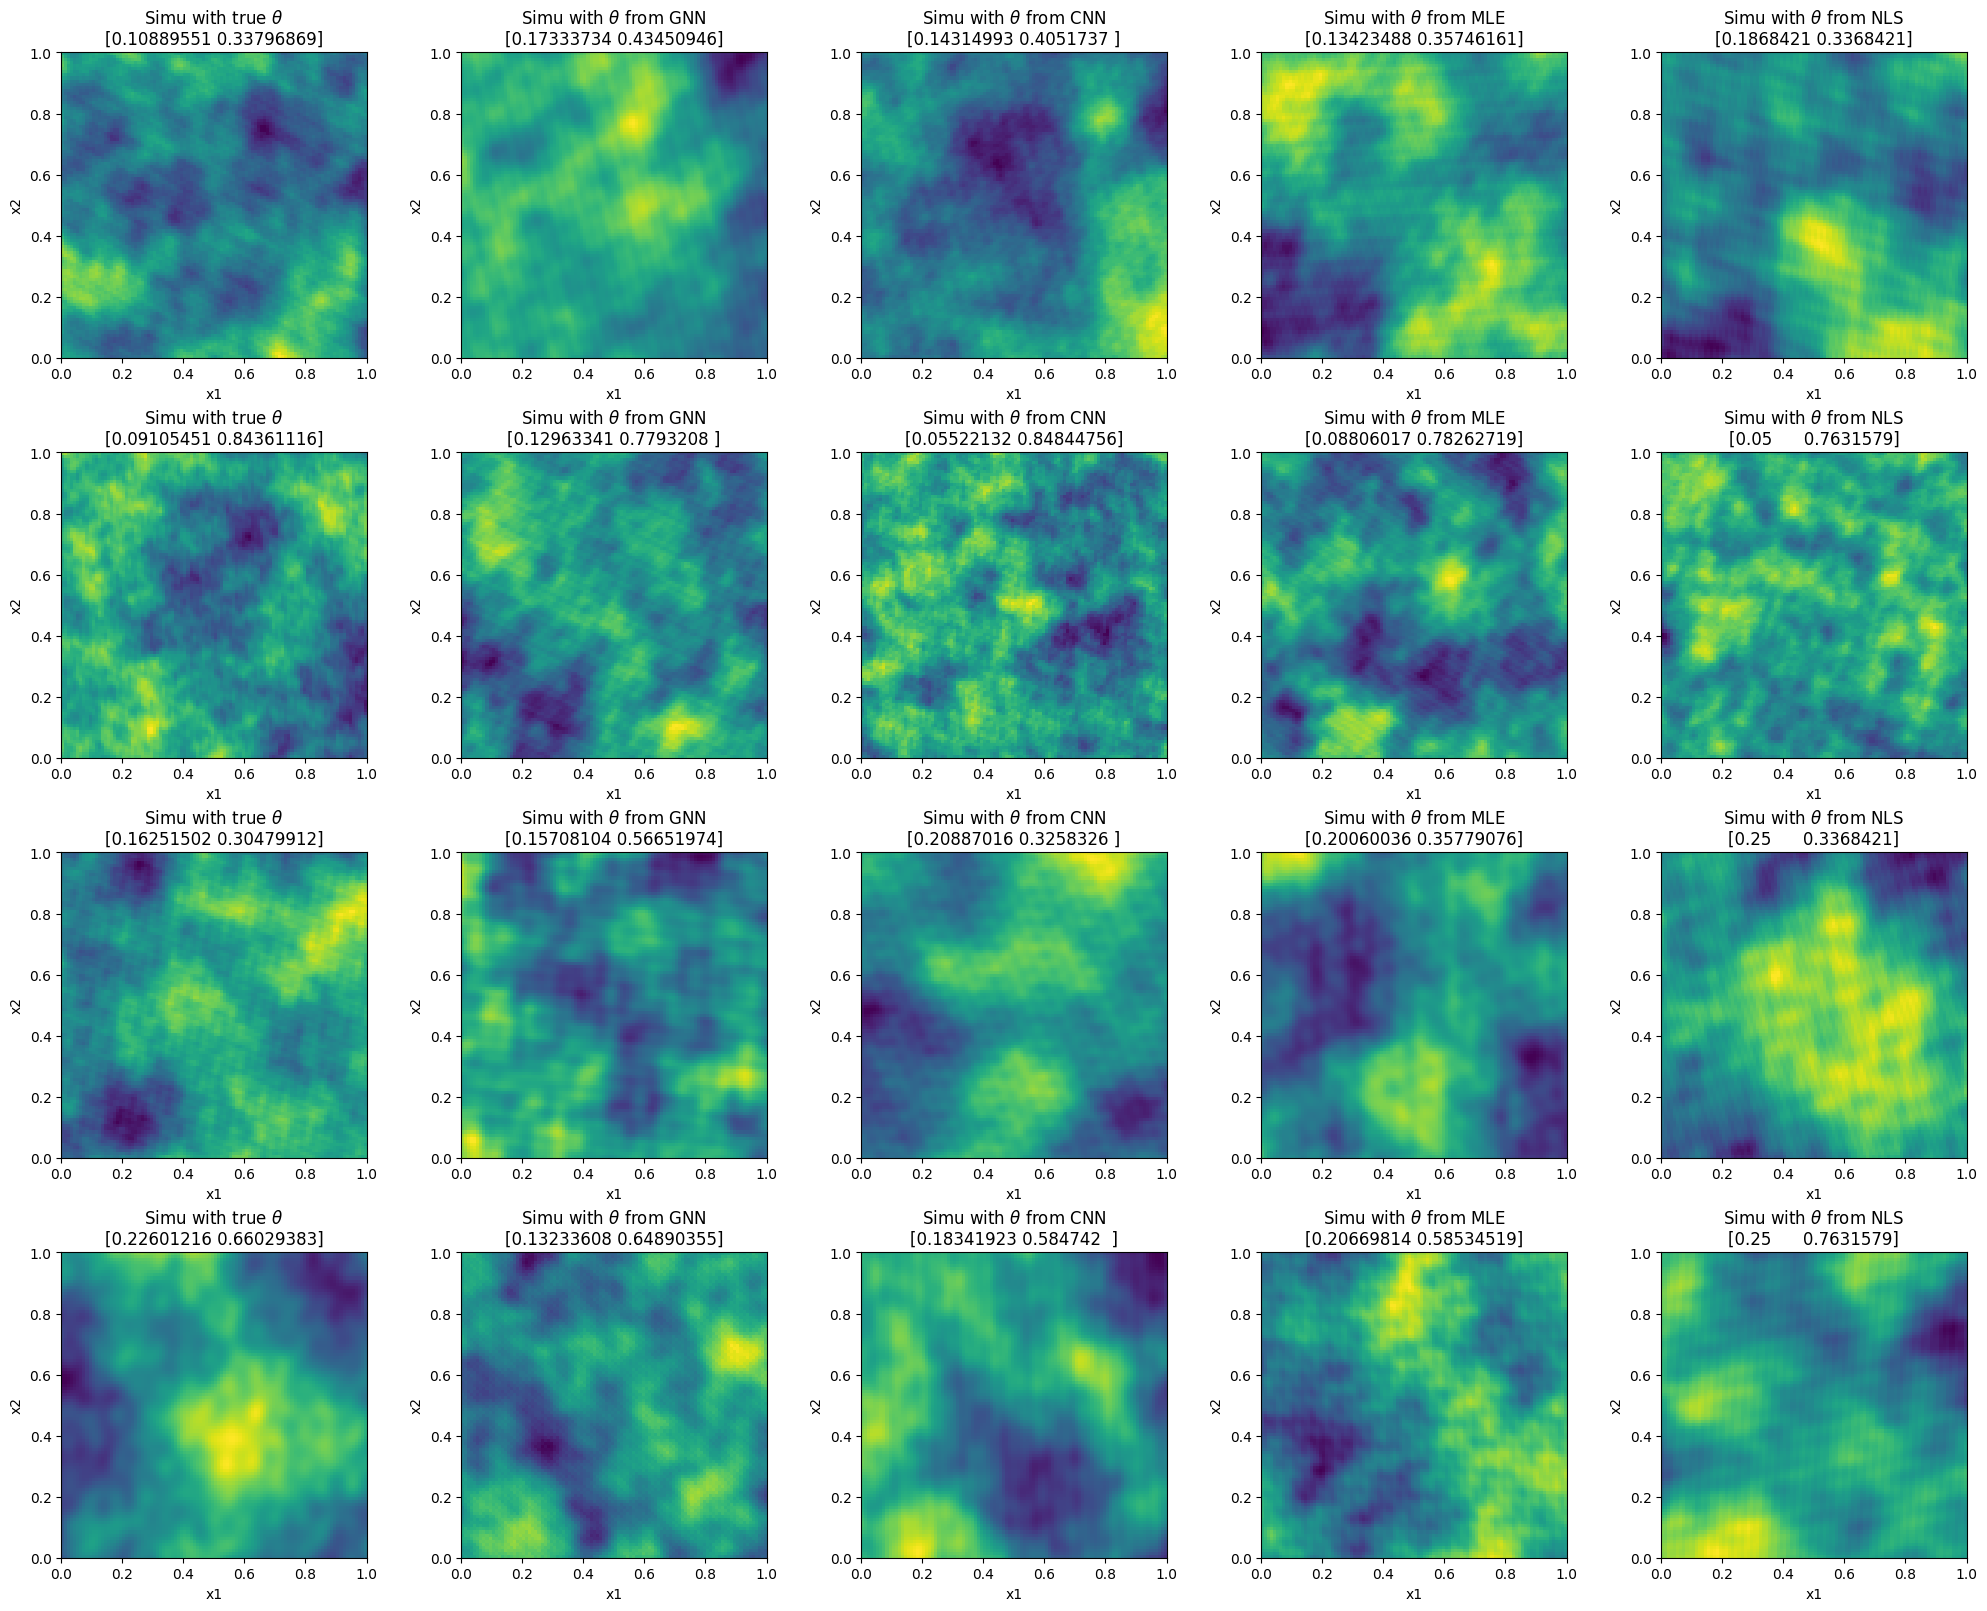

In [47]:
n = 4
fig_map, axs = plt.subplots(n, 5, figsize=(20,n*4), constrained_layout=True)

methods = ["GNN", "CNN", "MLE", "NLS"]
thetas_final = [theta_final_graph, theta_final_grid, theta_final_ML, theta_final_nls]
losses = [all_loss_test_graph[-1], all_loss_test_grid[-1], all_loss_test_ML, all_loss_test_nls]

for i in range(n):
    true_theta = sampling_test[i][1].detach().numpy()
    sample = simulation_matern(grid(), true_theta[0], true_theta[1], plot=False)
    
    sample = sample['Simu'].reshape(100, 100)
    axs[i,0].imshow(sample, cmap='viridis', extent=[0,1,0,1])
        
    axs[i,0].set_xlabel('x1')
    axs[i,0].set_ylabel('x2')
    axs[i,0].set_title(r'Simu with true $\theta$'+'\n'+str(true_theta))
    
    for j, (method, thetas, l) in enumerate(zip(methods, thetas_final,losses)) :

        sample = simulation_matern(grid(), thetas[i,0], thetas[i,1], plot=False)
            
        sample = sample['Simu'].reshape(100, 100)
        axs[i,j+1].imshow(sample, cmap='viridis', extent=[0,1,0,1]) #, origin='lower', extent=[0,1,0,1], cmap='viridis')
            
        axs[i,j+1].set_xlabel('x1')
        axs[i,j+1].set_ylabel('x2')
        axs[i,j+1].set_title(r'Simu with $\theta$ from '+method+'\n'+str(thetas[i]))
        

plt.show()

# fig_map.savefig(path+"/conclusion_graphs"+"/visualisation.pdf", format="pdf", bbox_inches="tight")
fig_map.savefig(path+"/conclusion_graphs"+"/visualisation.png", format="png", bbox_inches="tight")

tensor([0.1525, 0.5463], dtype=torch.float64)


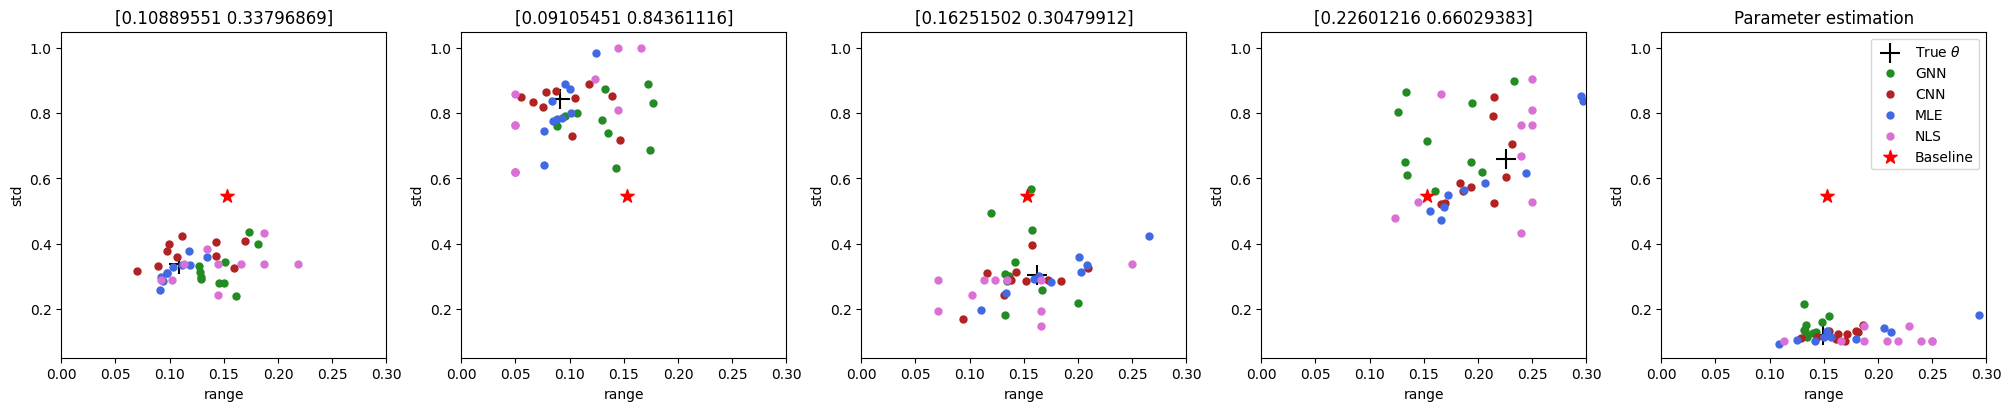

In [48]:
methods = ["GNN", "CNN", "MLE", "NLS"]
colors = ["forestgreen", "firebrick", "royalblue", "orchid"]
thetas_final = [theta_final_graph, theta_final_grid, theta_final_ML, theta_final_nls]

fig_target, axs = plt.subplots(1, 5, figsize=(20,4), constrained_layout=True)

_, based = baseline_mae(dataset_graph)
print(based)

for j in range(min(m_test,5)):
    
    true_theta = sampling_test[j][1].detach().numpy()

    axs[j].scatter(true_theta[0], true_theta[1], s=200, color='black', marker="+", label=r"True $\theta$") 
        
    axs[j].set_xlabel('range')
    axs[j].set_ylabel('std')
    axs[j].set_title(str(true_theta))

    axs[j].set_xlim([range_min-.05, range_max+.05])
    axs[j].set_ylim([std_min-.05, std_max+.05])

    for method, color, thetas in zip(methods, colors, thetas_final) :

        axs[j].scatter(thetas[np.arange(n_test)*m_test+j,0],
                       thetas[np.arange(n_test)*m_test+j,1],
                       s=100, color=color, marker=".", label=method) 

    axs[j].scatter(based[0],based[1], s=100, color='red', marker="*",label='Baseline')

plt.title("Parameter estimation")
plt.legend()

# fig_target.savefig(path+"/conclusion_graphs"+"/target.pdf", format="pdf", bbox_inches="tight")
fig_target.savefig(path+"/conclusion_graphs"+"/target.png", format="png", bbox_inches="tight")

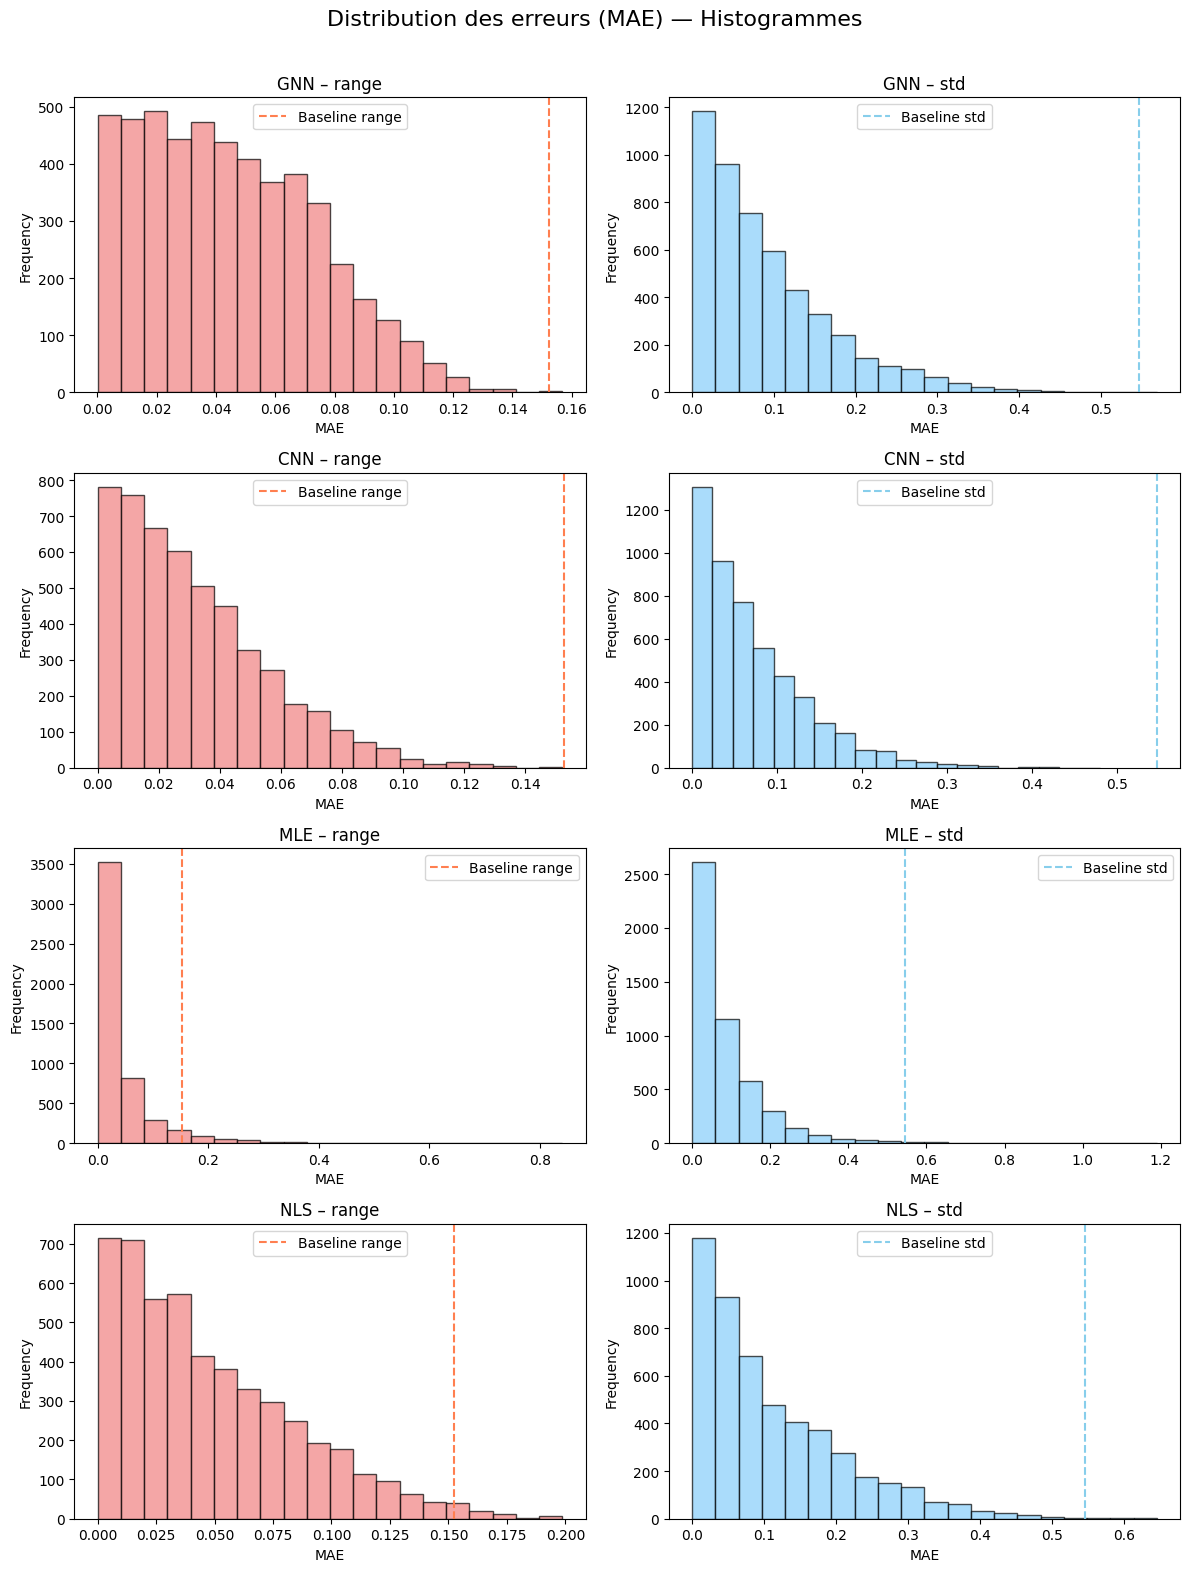

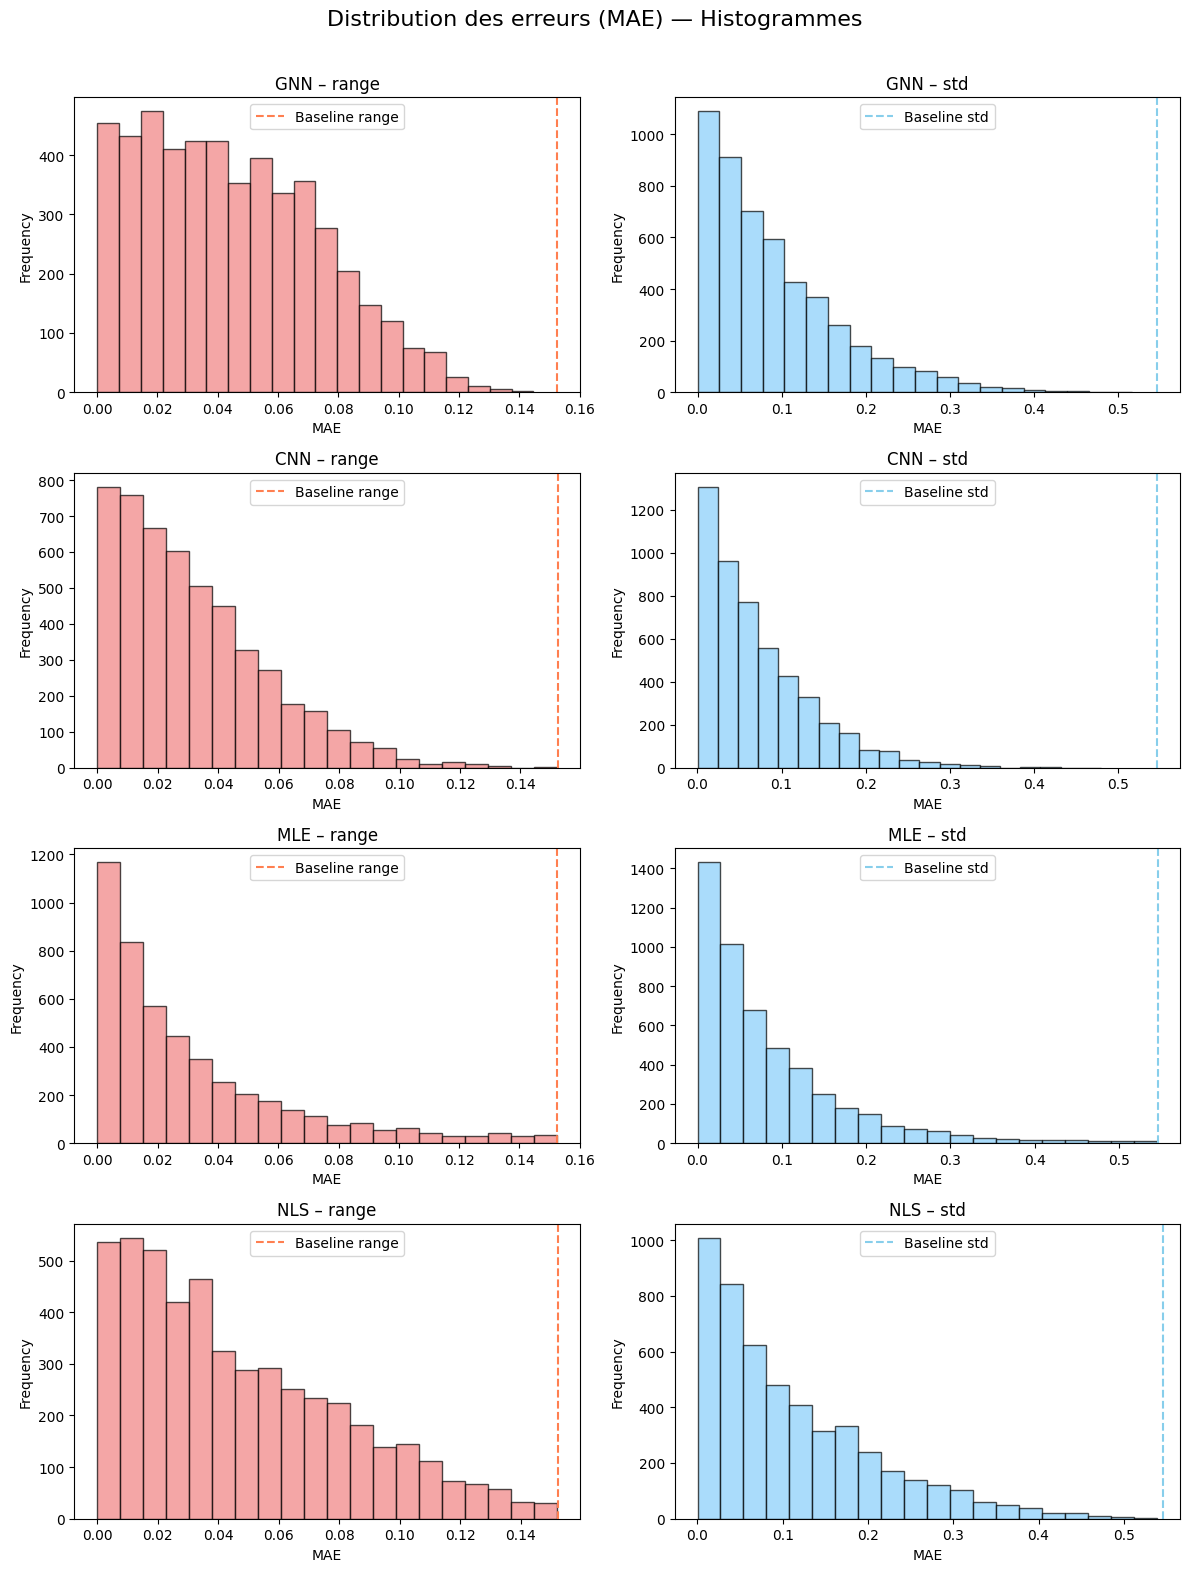

In [61]:
methods = ['GNN', 'CNN', 'MLE', 'NLS']

loss_range = [
    all_loss_test_graph[-1][:, 0],
    all_loss_test_grid[-1][:, 0],
    all_loss_test_ML[:, 0],
    all_loss_test_nls[:, 0]
]

loss_std = [
    all_loss_test_graph[-1][:, 1],
    all_loss_test_grid[-1][:, 1],
    all_loss_test_ML[:, 1],
    all_loss_test_nls[:, 1]
]

fig_hist, axs = plt.subplots(len(loss_range), 2, figsize=(12, 4*len(loss_range)))
fig_hist.suptitle("Distribution des erreurs (MAE) — Histogrammes", fontsize=16)

for i, method in enumerate(methods):

    axs[i, 0].hist(loss_range[i], bins=20, color='lightcoral', alpha=0.7, edgecolor='black')
    axs[i, 0].axvline(based[0], color='coral', linestyle='--', label='Baseline range')
    axs[i, 0].set_title(f"{method} – range")
    axs[i, 0].set_xlabel("MAE")
    axs[i, 0].set_ylabel("Frequency")
    axs[i, 0].legend()

    axs[i, 1].hist(loss_std[i], bins=20, color='lightskyblue', alpha=0.7, edgecolor='black')
    axs[i, 1].axvline(based[1], color='skyblue', linestyle='--', label='Baseline std')
    axs[i, 1].set_title(f"{method} – std")
    axs[i, 1].set_xlabel("MAE")
    axs[i, 1].set_ylabel("Frequency")
    axs[i, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig_hist.savefig(path+"/conclusion_graphs"+"/score_test_hist.png", format="png", bbox_inches="tight")

loss_range = [
    all_loss_test_graph[-1][:, 0][all_loss_test_graph[-1][:, 0] < based[0].detach().numpy()],
    all_loss_test_grid[-1][:, 0][all_loss_test_grid[-1][:, 0] < based[0].detach().numpy()],
    all_loss_test_ML[:, 0][all_loss_test_ML[:, 0] < based[0].detach().numpy()],
    all_loss_test_nls[:, 0][all_loss_test_nls[:, 0] < based[0].detach().numpy()]
]

loss_std = [
    all_loss_test_graph[-1][:, 1][all_loss_test_graph[-1][:, 1] < based[1].detach().numpy()],
    all_loss_test_grid[-1][:, 1][all_loss_test_grid[-1][:, 1] < based[1].detach().numpy()],
    all_loss_test_ML[:, 1][all_loss_test_ML[:, 1] < based[1].detach().numpy()],
    all_loss_test_nls[:, 1][all_loss_test_nls[:, 1] < based[1].detach().numpy()]
]

fig_hist, axs = plt.subplots(len(loss_range), 2, figsize=(12, 4*len(loss_range)))
fig_hist.suptitle("Distribution des erreurs (MAE) — Histogrammes", fontsize=16)

for i, method in enumerate(methods):

    axs[i, 0].hist(loss_range[i], bins=20, color='lightcoral', alpha=0.7, edgecolor='black')
    axs[i, 0].axvline(based[0], color='coral', linestyle='--', label='Baseline range')
    axs[i, 0].set_title(f"{method} – range")
    axs[i, 0].set_xlabel("MAE")
    axs[i, 0].set_ylabel("Frequency")
    axs[i, 0].legend()

    axs[i, 1].hist(loss_std[i], bins=20, color='lightskyblue', alpha=0.7, edgecolor='black')
    axs[i, 1].axvline(based[1], color='skyblue', linestyle='--', label='Baseline std')
    axs[i, 1].set_title(f"{method} – std")
    axs[i, 1].set_xlabel("MAE")
    axs[i, 1].set_ylabel("Frequency")
    axs[i, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig_hist.savefig(path+"/conclusion_graphs"+"/score_test_hist_cropped.png", format="png", bbox_inches="tight")

In [50]:
results = {
    "all_loss_train": {
        "GNN": all_loss_train_graph,
        "CNN": all_loss_train_grid,
    },
    "all_loss_test": {
        "GNN": all_loss_test_graph,
        "CNN": all_loss_test_grid,
        "MLE": all_loss_test_ML,
        "NLS": all_loss_test_nls,
    },
    "theta_final": {
        "GNN": theta_final_graph,
        "CNN": theta_final_grid,
        "MLE": theta_final_ML,
        "NLS": theta_final_nls,
    },
    "times": {
        "time_train_graph": time_train_graph,
        "time_test_graph": time_test_graph,
        "time_train_grid": time_train_grid,
        "time_test_grid": time_test_grid,
        "time_test_ML": time_test_ML,
        "time_train_nls": time_train_nls,
        "time_test_nls": time_test_nls,
    },
    "meta": {
        "n_train": n_train, "m_train": m_train,
        "n_test": n_test, "m_test": m_test,
    }
}

torch.save(results, path + "/results.pt")

## Bonus

In [ ]:
# bounds = [(range_min, range_max), (std_min, std_max)]

# def nls_optim(data, theta0=(.2, .5)):

#     def obj(theta):
#         theta_t = torch.tensor(theta, dtype=torch.float32).unsqueeze(0).to(device)
#         h = model_nls(data.unsqueeze(0), theta=theta_t)
#         p = torch.softmax(h, dim=1)[:, 1]   
#         L = p / (1 - p)
            
#         # L = torch.log(L.unsqueeze(0)).detach().numpy()
#         # L = lg.predict_proba(L.T)[0, 1]
        
#         return -float(L)
        
#     res = minimize(obj, theta0, method="Nelder-Mead", bounds=bounds, options={"maxiter":2000})  
#     return res.x, res

def nls_optim(data, theta0=torch.tensor((.1, .5))):

    def obj(theta):
        theta_t = theta.unsqueeze(0).to(device)
        h = model_nls(data.unsqueeze(0), theta=theta_t)
        p = torch.softmax(h, dim=1)[:, 1]   
        L = p / (1 - p)
        
        return -L

    with torch.no_grad() :
        res = torchmin.minimize(obj, theta0, method="newton-exact", options={"max_iter":4000})  # bfgs, newton-cg
        return res.x, res


all_loss_test_nls = []

time_test_nls = time.time()

for i, (data_test, theta_test, _) in enumerate(dataset_grid_test) : 

    output, _ = nls_optim(data_test)

    all_loss_test_nls.append(np.abs(output - np.array(theta_test)))

    # print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_nls = time.time() - time_test_nls

print(f"\nTime to test : {time_test_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_nls,axis=0), "±", np.std(all_loss_test_nls,axis=0))

In [ ]:
class CNN_network_nodense(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(16)
        self.conv_out = nn.Sequential(
            nn.Conv2d(hidden, hidden//2, 4, padding=0,stride=4),
            nn.ReLU(),
            nn.Dropout2d(p=0.05),
            nn.Conv2d(hidden//2, 2, 4, padding=0,stride=4)
        )

    def forward(self, x, deepset):
        
        h = self.conv(x)
        
        h = self.pool(h)

        h_shape = torch.tensor(h.shape)
            
        h = global_mean_pool(h.reshape((h_shape[0], -1)), deepset)   # [nb_deepset, hidden_dim]

        h = h.view(h.size(0), h_shape[1], h_shape[2], h_shape[3])
        out = self.conv_out(h)
        out = out.view(h.shape[0], -1)
        
        return out

def train_cnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = []

    for i, (batched_data, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device), theta.to(device), deepset.to(device)

        deepset_mapped, theta = map_deepset(deepset, theta)
        
        output = model(batched_data, deepset_mapped)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss.append(torch.abs(output - theta))

    return torch.cat(sum_loss,dim=0)

model_grid_nodense = CNN_network_nodense(in_channels=2).to(device)

optimizer_grid_nodense = torch.optim.Adam(model_grid_nodense.parameters(), lr=1e-4)

all_loss_train_grid_nodense = [] # torch.zeros((n_epochs, n_train,theta_size))
all_loss_test_grid_nodense = [] # torch.zeros((n_epochs//n_epochs_test, n_test,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_grid_nodense = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid_nodense,
        optimizer_grid_nodense,
        loader_grid,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_grid_nodense.append(loss.detach().numpy())

    # test
    if (epoch+1)%n_epochs_test == 0 :
        time_test_grid_nodense = time.time()
        for data_test, theta_test, deepset_test in loader_grid_test : 
            # deepset_mapped_test, theta_test = map_deepset(deepset_test, theta_test)
            # output = model_grid_nodense(data_test,deepset_mapped_test)
            output = model_grid_nodense(data_test,torch.arange(len(theta_test)))
            l = torch.abs(output - theta_test)
        time_test_grid_nodense = time.time() - time_test_grid_nodense
        time_train_grid_nodense -= time_test_grid_nodense
        all_loss_test_grid_nodense.append(l.detach().numpy())
        theta_final_grid_nodense = output.detach().numpy()

time_train_grid_nodense = time.time() - time_train_grid_nodense

print(f"Time to train : {time_train_grid_nodense:.2f}s")

print("Train loss :", np.mean(all_loss_train_grid_nodense[-1],axis=0), "±", np.std(all_loss_train_grid_nodense[-1],axis=0))
print("Test loss :", np.mean(all_loss_test_grid_nodense[-1],axis=0), "±", np.std(all_loss_test_grid_nodense[-1],axis=0))

fig_cnn_nodense, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot([l.mean(axis=0)[0] for l in all_loss_train_grid_nodense], 'orangered', label='train range')
ax[1].plot([l.mean(axis=0)[1] for l in all_loss_train_grid_nodense], 'deepskyblue',label='train std')
ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[0] for l in all_loss_test_grid_nodense], 'coral', label='test range')
ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[1] for l in all_loss_test_grid_nodense], 'skyblue',label='test std')

based, _ = baseline_mae(dataset_grid)
ax[0].axhline(based[0],color='lightcoral', ls='--', label='range baseline')
plt.axhline(based[1],color='lightskyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

fig_cnn_nodense.savefig(path+"/bonus"+"/cnn-nodense_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_grid_nodense.state_dict(), path+"/bonus"+"/cnn-nodense_model.pth")

In [ ]:
def w_first_half(distances, threshold=0.4, nb_intervals=10, epsilon=1e-5, std=0.00375):
    """
    exp(-(d_jj' _ µ_1)²/σ²), ..., exp(-(d_jj' _ µ_10)²/σ²)
    """
    
    if torch.max(distances) < epsilon or torch.max(distances) > threshold:
        raise ValueError(distances,threshold,"Distance should be within the range (0, threshold]")
    
    interval_length = threshold / nb_intervals
    interval_index = (distances / interval_length).to(torch.int)
    interval_index[interval_index == nb_intervals] -= 1

    means = torch.arange(interval_length/2,threshold,interval_length).tile((len(distances),1))
    
    res = distances.tile((1,nb_intervals))
    res = (res - means)**2 / (2 * std**2)
    
    return torch.exp(-res)


def w_first_half_old(distance, threshold=0.4, epsilon=1e-5):
    if distance < epsilon or distance > threshold:
        raise ValueError(distance,threshold,"Distance should be within the range (0, threshold]")
    
    interval_length = threshold / 10
    interval_index = int(distance / interval_length)
    if interval_index == 10:
        interval_index = 9
    
    one_hot = torch.zeros(10, device=device)
    one_hot[interval_index] = 1
    
    return one_hot

class w_second_half(nn.Module):
    """
    ω(d_jj'), MLP
    """
    def __init__(self, input_dim, hidden_dim, edge_output_dim):
        super(w_second_half, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, edge_output_dim)
        ).to(device) 

    def forward(self, x):
        return self.mlp(x)

class w_tilde(nn.Module):
    """
    w̃_j(s_j, s_j') = w_j(s_j, s_j') ⊘ Σ_j'' w_j(s_j, s_j'') 

    w(d_jj') = [exp(-(d_jj' _ µ_1)²/σ²), ..., exp(-(d_jj' _ µ_10)²/σ²), ω(d_jj')]
    """
    def __init__(self, in_channels, edge_hidden_dim, edge_output_dim, threshold=.4):
        super(w_tilde, self).__init__()
        
        self.edge_mlp = w_second_half(in_channels, edge_hidden_dim, edge_output_dim)
        self.threshold = threshold
    
    def forward(self, data):

        x, edge_index, edge_attr = data.x.to(device), data.edge_index.to(device), data.edge_attr.to(device)

        w_first = w_first_half(edge_attr, threshold=self.threshold).to(device)
        # w_first = torch.stack([w_first_half_old(d.item(),self.threshold) for d in edge_attr]).to(device)
        w_second = self.edge_mlp(edge_attr)
        w = torch.cat((w_first, w_second), dim=1) 

        d = scatter(w, edge_index[0], reduce = 'sum')  # sum over all neighbors
        dtilde = d[edge_index[0]]  
        
        mask = dtilde != 0
        replacement_tensor = torch.ones_like(mask, device=device) * 1e-5
        wtilde = torch.where(mask, w / dtilde, replacement_tensor) 
        
        data.edge_attr_wtilde = wtilde
        
        return data

class h(MessagePassing):  
    """
    h_j = g(Γ_1 @ h_(j-1) + Γ_2 @ ĥ_j + b), Convolution layer

    ĥ_j = Σ_j' w(d_jj') × ρ(h_j, h_j'), with h_j, h_j' from previous layer

    ρ(h_j, h_j') = |a h_j - (1-a) h_j'|^b
    """
    
    def __init__(self, hidden_channels, moovingvaluegamma1):
        super().__init__(aggr='add')
        
        self.a = nn.Parameter(torch.rand(1, device=device)) # a in [0, 1]
        self.b = nn.Parameter(torch.rand(1, device=device) + 1) # b > 0
        
        self.gamma1 = nn.Parameter(torch.rand(hidden_channels, moovingvaluegamma1, device=device))
        self.gamma2 = nn.Parameter(torch.rand(hidden_channels, hidden_channels, device=device))
        
        self.biax = nn.Parameter(torch.rand(hidden_channels,1, device=device))
    
    def forward(self, x: torch.Tensor, edge_index: torch.Tensor,
                edge_attr: torch.Tensor ) -> torch.Tensor:
        
        hbar = self.propagate(edge_index, x = x, edge_attr = edge_attr) 
        
        hbar = hbar.transpose(1,0)
        x = x.transpose(1,0)
        
        out = self.gamma1 @ x + self.gamma2 @ hbar + self.biax
        out = out.transpose(1,0)
        out = torch.nn.ReLU()(out).squeeze()

        return out

    def message(self, x_i, x_j, edge_attr: torch.Tensor) -> torch.Tensor:
        
        rho = (torch.abs(self.a * x_i - (1 - self.a) * x_j)) ** self.b

        return rho * edge_attr


class exp_final(nn.Module):
    def forward(self, x):
        return torch.exp(x)

class phi(nn.Module):
    """
    ɸ, MLP, mapping layer
    """
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(phi, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
            # exp_final(), # In case we are looking to log of the targets
        )

    def forward(self, pooled_feature):
        device=pooled_feature.device
        out = self.mlp(pooled_feature.to(device))
        return out


class GNN_network(nn.Module):

    def __init__(self, in_channels, gamma1_1=1, gamma1_2=20, hidden_dim=20, edge_hidden_dim=64, edge_output_dim=10, threshold=0.40,mapping_hidden_dim=64, final_output_dim=2):# final_output_dim, mapping_hidden_dim, threshold):
        super(GNN_network, self).__init__()
        
        self.wtilde_initial = w_tilde(in_channels, edge_hidden_dim, edge_output_dim, threshold)
        self.special_conv1 = h(hidden_dim,gamma1_1)

        # We can repeat those two lines
        self.wtilde = w_tilde(in_channels, edge_hidden_dim, edge_output_dim, threshold) 
        self.special_conv2 = h(hidden_dim,gamma1_2)
        
        self.mapping = phi(hidden_dim, mapping_hidden_dim, final_output_dim)

    def forward(self, data, deepset):
        data = data.to(device)

        data = self.wtilde_initial(data)
        data.x = self.special_conv1(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attr_wtilde)
        
        data=self.wtilde(data)
        data.x=self.special_conv2(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attr_wtilde)
        
        pooled_graphs = global_mean_pool(data.x, data.batch) 
        
        mapping = {old: new for new, old in enumerate(deepset.unique().tolist())}
        deepset_mapped = torch.tensor([mapping[int(ds)] for ds in deepset], device=deepset.device)
            
        pooled_graphs = global_mean_pool(pooled_graphs, deepset_mapped)   # [nb_deepset, hidden_dim]
        
        out = self.mapping(pooled_graphs)
        out = out.view(-1)
        
        return torch.reshape(out,(-1,theta_size))

def train_gnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = []

    for i, (batched_data, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device), theta.to(device), deepset.to(device)

        deepset_mapped, theta = map_deepset(deepset, theta)

        output = model(batched_data, deepset_mapped)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss.append(torch.abs(output - theta))

    return torch.cat(sum_loss,dim=0)

model_graph_complex = GNN_network(in_channels=1)

optimizer_graph_complex = torch.optim.Adam(model_graph_complex.parameters(), lr=5e-5)

all_loss_train_graph_complex = [] # torch.zeros((n_epochs, n_train,theta_size))
all_loss_test_graph_complex = [] # torch.zeros((n_epochs//n_epochs_test, n_test,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_graph_complex = time.time()

for epoch in t:
    
    loss = train_gnn(
        model_graph_complex,
        optimizer_graph_complex,
        loader_graph,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_graph_complex.append(loss.detach().numpy())

    # test
    if (epoch+1)%n_epochs_test == 0 :
        time_test_graph_complex = time.time()
        for data_test, theta_test, deepset_test in loader_graph_test : 
            # deepset_mapped_test, theta_test = map_deepset(deepset_test, theta_test)
            # output = model_graph_complex(data_test,deepset_mapped_test)
            output = model_graph_complex(data_test,torch.arange(len(theta_test)))
            l = torch.abs(output - theta_test)
        time_test_graph_complex = time.time() - time_test_graph_complex
        time_train_graph_complex -= time_test_graph_complex
        all_loss_test_graph_complex.append(l.detach().numpy())
        theta_final_graph_complex = output.detach().numpy()

time_train_graph_complex = time.time() - time_train_graph_complex

print(f"Time to train : {time_train_graph_complex:.2f}s")

# all_loss_train_graph_complex = torch.stack(all_loss_train_graph_complex).detach().numpy()
# all_loss_test_graph_complex = torch.stack(all_loss_test_graph_complex).detach().numpy()
print("Train loss :", np.mean(all_loss_train_graph_complex[-1],axis=0), "±", np.std(all_loss_train_graph_complex[-1],axis=0))
print("Test loss :", np.mean(all_loss_test_graph_complex[-1],axis=0), "±", np.std(all_loss_test_graph_complex[-1],axis=0))

fig_gnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot([l.mean(axis=0)[0] for l in all_loss_train_graph_complex], 'orangered', label='train range')
ax[1].plot([l.mean(axis=0)[1] for l in all_loss_train_graph_complex], 'deepskyblue',label='train std')
ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[0] for l in all_loss_test_graph_complex], 'coral', label='test range')
ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[1] for l in all_loss_test_graph_complex], 'skyblue',label='test std')

based, _ = baseline_mae(dataset_graph)
ax[0].axhline(based[0],color='lightcoral', ls='--', label='range baseline')
plt.axhline(based[1],color='lightskyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].set_ylim(top=.5)
ax[1].set_ylim(top=.5)
ax[0].legend()
ax[1].legend()

fig_gnn.savefig(path+"/bonus"+"/gnn_complex_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_graph_complex.state_dict(), path+"/bonus"+"/gnn_complex_model.pth")

In [ ]:
results = {
    "all_loss_train": {
        "GNN": all_loss_train_graph,
        "CNN": all_loss_train_grid,
        "GNN_complex": all_loss_train_graph_complex,
        "CNN_nodense": all_loss_train_grid_nodense,
    },
    "all_loss_test": {
        "GNN": all_loss_test_graph,
        "CNN": all_loss_test_grid,
        "MLE": all_loss_test_ML,
        "GNN_complex": all_loss_test_graph_complex,
        "CNN_nodense": all_loss_test_grid_nodense,
    },
    "theta_final": {
        "GNN": theta_final_graph,
        "CNN": theta_final_grid,
        "MLE": theta_final_ML,
        "NLS": theta_final_nls,
        "GNN_complex": theta_final_graph_complex,
        "CNN_nodense": theta_final_grid_nodense,
    },
    "times": {
        "time_train_graph": time_train_graph,
        "time_test_graph": time_test_graph,
        "time_train_grid": time_train_grid,
        "time_test_grid": time_test_grid,
        "time_test_ML": time_test_ML,
        "time_train_nls": time_train_nls,
        "time_test_nls": time_test_nls,
        "time_train_graph_complex": time_train_graph_complex,
        "time_test_graph_complex": time_test_graph_complex,
        "time_train_nls": time_train_grid_nodense,
        "time_test_nls": time_test_grid_nodense,
    },
    "meta": {
        "n_train": n_train, "m_train": m_train,
        "n_test": n_test, "m_test": m_test,
    }
}

torch.save(results, path + "/bonus" + "/results.pt")